In [10]:

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

ROOT = Path.cwd()

BASIC_DIR = ROOT / "maze_metric_outputs_basic"
ASYM_DIR = ROOT / "maze_metric_outputs_asymmetric"

FIG_DIR = ROOT / "paper_figures" / "figure_asymmetric"
FIG_DIR.mkdir(parents=True, exist_ok=True)

PS = [0.0, 0.01, 0.03, 0.05, 0.1]
SEEDS = [str(i) for i in range(10)]
PROGRESS = list(range(15, 100, 10))

EARLY = (0.2, 0.3)
LATE = (0.9, 1.0)

p_vals = np.array(sorted(PS), dtype=float)
norm = mpl.colors.Normalize(vmin=p_vals.min(), vmax=p_vals.max())
cmap = mpl.colormaps["cividis"]

P_COLORS = {
    p: cmap(0.18 + 0.70 * norm(p))
    for p in p_vals
}

P_MARKERS = {
    0.00: "o",
    0.01: "s",
    0.03: "^",
    0.05: "D",
    0.10: "P",
}

DYNAMICS_METRICS = {
    "linear_depth_r2": "Linear depth\ndecodability ($R^2$)",
    "transition_consistency": "Local direction\nconsistency",
    "tortuosity": "Latent trajectory\ntortuosity",
    "transition_balanced_ce": "Balanced CE (nats)",
    "success_rate": "Success rate",
    "steps_success": "Steps to reward",
}

COLORS = {
    "ink": "#30363A",
    "grid": "#DFE7E5",
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9.5,
    "axes.labelsize": 9.5,
    "axes.titlesize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "axes.linewidth": 0.8,
    "axes.edgecolor": COLORS["ink"],
    "text.color": COLORS["ink"],
    "xtick.color": COLORS["ink"],
    "ytick.color": COLORS["ink"],
    "lines.linewidth": 2.0,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=COLORS["grid"], linewidth=0.6)
    ax.tick_params(
        direction="out",
        length=3,
        width=0.8,
        colors=COLORS["ink"]
    )


def save_figure(fig, name):
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(
            FIG_DIR / f"{name}.{ext}",
            dpi=300,
            bbox_inches="tight"
        )


dynamics = pd.read_csv(
    ASYM_DIR / "summary.csv",
    dtype={"seed": str}
)

dynamics["progress"] = (
    (dynamics["window_start"] + dynamics["window_end"]) * 50
).round(4)

dynamics["p"] = dynamics["p"].round(6)

dynamics = dynamics[
    dynamics["seed"].isin(SEEDS)
    & dynamics["p"].isin(PS)
    & dynamics["progress"].isin(PROGRESS)
].copy()

counts = (
    dynamics.groupby(["p", "progress"])["seed"]
    .nunique()
    .unstack()
    .reindex(index=PS, columns=PROGRESS)
)

if counts.isna().any().any():
    raise ValueError("Some p values or training windows are missing.")

display(counts)


progress,15,25,35,45,55,65,75,85,95
p,,,,,,,,,
0.00,10,10,10,10,10,10,10,10,10
0.01,10,10,10,10,10,10,10,10,10
0.03,10,10,10,10,10,10,10,10,10
0.05,10,10,10,10,10,10,10,10,10
0.10,10,10,10,10,10,10,10,10,10


In [11]:

stats_list = []

for metric in DYNAMICS_METRICS:
    stats = (
        dynamics.groupby(["p", "progress"])[metric]
        .agg(["mean", "sem", "count"])
        .reset_index()
    )

    stats["metric"] = metric
    stats_list.append(stats)

dynamics_stats = pd.concat(stats_list, ignore_index=True)

dynamics_stats.to_csv(
    FIG_DIR / "asymmetric_dynamics_mean_sem.csv",
    index=False
)


def plot_dynamics(ax, metric, show_xlabel=True):
    style_axis(ax)

    ax.set_xlim(14, 96)
    ax.set_xticks(np.arange(15, 100, 10))
    ax.margins(x=0.01)

    df = dynamics_stats[dynamics_stats["metric"] == metric]

    for p in PS:
        d = df[np.isclose(df["p"], p)].sort_values("progress")

        if d.empty:
            continue

        ax.errorbar(
            d["progress"],
            d["mean"],
            yerr=d["sem"].fillna(0),
            marker=P_MARKERS[p],
            color=P_COLORS[p],
            linestyle="-",
            markersize=4.0,
            markeredgecolor="white",
            markeredgewidth=0.5,
            linewidth=2.0,
            elinewidth=0.9,
            capsize=2.0,
            capthick=0.9,
            label=rf"$p={p:g}$",
            zorder=3
        )

    ax.set_ylabel(
        DYNAMICS_METRICS[metric],
        color=COLORS["ink"]
    )

    if show_xlabel:
        ax.set_xlabel("Training progress (window midpoint, %)")
    else:
        ax.tick_params(labelbottom=False)

    if metric == "success_rate":
        ax.set_ylim(0, 1.02)


In [12]:

KEYS = ["p", "seed", "window_start", "window_end"]

METRICS = dict(DYNAMICS_METRICS)

MODEL_COLORS = {
    "Symmetric maze": "#18545D",
    "Asymmetric maze": "#B66549",
}

MODEL_MARKERS = {
    "Symmetric maze": "o",
    "Asymmetric maze": "s",
}


def load_metrics(folder, label):
    path = folder / "summary.csv"

    if not path.is_file():
        raise FileNotFoundError(path)

    df = pd.read_csv(path, dtype={"seed": str})

    missing = set(KEYS + list(METRICS)) - set(df.columns)
    if missing:
        raise KeyError(f"{label}: missing {sorted(missing)}")

    for col in ("p", "window_start", "window_end"):
        df[col] = pd.to_numeric(df[col]).round(6)

    behavior_path = folder / "behavior_metrics.csv"

    if behavior_path.is_file():
        behavior = pd.read_csv(behavior_path, dtype={"seed": str})

        if set(KEYS + ["node_entropy"]).issubset(behavior.columns):
            for col in ("p", "window_start", "window_end"):
                behavior[col] = pd.to_numeric(behavior[col]).round(6)

            if behavior.duplicated(KEYS).any():
                raise ValueError(f"Duplicate behavior metrics: {behavior_path}")

            df = df.drop(columns=["node_entropy"], errors="ignore")

            df = df.merge(
                behavior[KEYS + ["node_entropy"]],
                on=KEYS,
                how="left",
                validate="one_to_one"
            )

    df = df[df["seed"].isin(SEEDS)].copy()

    if df.duplicated(KEYS).any():
        raise ValueError(f"{label}: duplicate run/window rows")

    if df.empty:
        raise ValueError(f"{label}: no data after filtering")

    print(
        f"{label}: {df['seed'].nunique()} seeds, "
        f"{df['p'].nunique()} p values"
    )

    return df


def within_window(df, window):
    return df[
        np.isclose(df["window_start"], window[0])
        & np.isclose(df["window_end"], window[1])
    ].copy()


def get_stats(df, metric, group_cols):
    d = df[group_cols + [metric]].copy()

    d[metric] = pd.to_numeric(d[metric], errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan)
    d = d.dropna(subset=[metric])

    out = (
        d.groupby(group_cols)[metric]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    out["sem"] = out["std"] / np.sqrt(out["count"])
    out["sem"] = out["sem"].fillna(0)

    return out


basic = load_metrics(BASIC_DIR, "Symmetric maze")
asym = load_metrics(ASYM_DIR, "Asymmetric maze")

shared_p = sorted(set(basic["p"]) & set(asym["p"]))

if not shared_p:
    raise ValueError("No common p values")

print("Common p values:", shared_p)


Symmetric maze: 10 seeds, 12 p values
Asymmetric maze: 10 seeds, 11 p values
Common p values: [0.0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1]


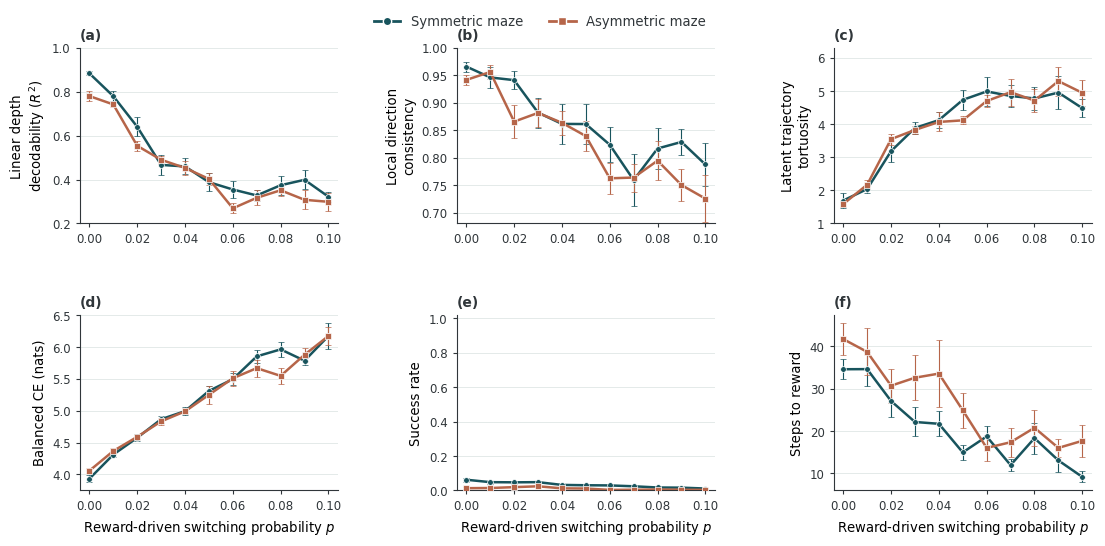

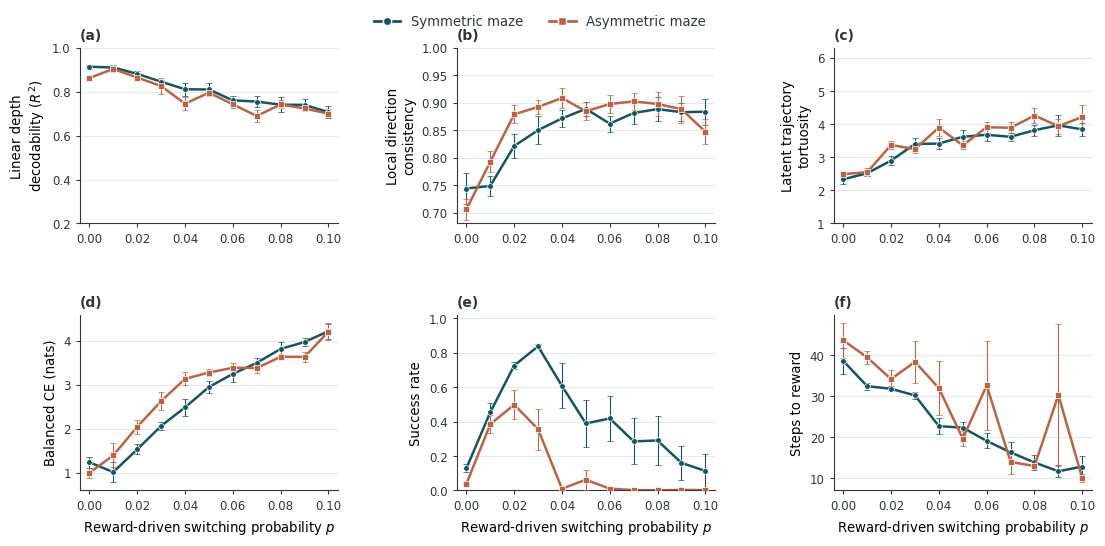

In [13]:

YLIMS = {
    "linear_depth_r2": (0.2, 1.0),
    "transition_consistency": (0.68, 1.00),
    "tortuosity": (1.0, 6.3),
}

comparison_stats = []

for label, df in [
    ("Symmetric maze", basic),
    ("Asymmetric maze", asym)
]:
    for window_name, window in [
        ("early", EARLY),
        ("late", LATE)
    ]:
        win_df = within_window(df, window)

        if win_df.empty:
            raise ValueError(
                f"{label}: missing {window_name} window"
            )

        win_df = win_df[win_df["p"].isin(shared_p)]

        for metric in METRICS:
            stats = get_stats(win_df, metric, ["p"])
            stats["model"] = label
            stats["window"] = window_name
            stats["metric"] = metric

            comparison_stats.append(stats)

comparison_stats = pd.concat(
    comparison_stats,
    ignore_index=True
)

comparison_stats.to_csv(
    FIG_DIR / "asymmetric_vs_symmetric_mean_sem.csv",
    index=False
)


def plot_comparison(ax, metric, window_name):
    style_axis(ax)

    for model in MODEL_COLORS:
        d = comparison_stats[
            (comparison_stats["metric"] == metric)
            & (comparison_stats["window"] == window_name)
            & (comparison_stats["model"] == model)
        ].sort_values("p")

        if d.empty:
            continue

        ax.errorbar(
            d["p"],
            d["mean"],
            yerr=d["sem"],
            color=MODEL_COLORS[model],
            marker=MODEL_MARKERS[model],
            markeredgecolor="white",
            markeredgewidth=0.5,
            markersize=4.1,
            linewidth=1.8,
            elinewidth=0.8,
            capsize=2,
            capthick=0.8,
            label=model,
            zorder=3
        )

    ax.set_ylabel(METRICS[metric])

    if metric in YLIMS:
        ax.set_ylim(*YLIMS[metric])
    elif metric in ("success_rate", "transition_coverage"):
        ax.set_ylim(0, 1.02)

    if len(shared_p) > 1:
        pad = max(
            (max(shared_p) - min(shared_p)) * 0.04,
            0.001
        )

        ax.set_xlim(
            min(shared_p) - pad,
            max(shared_p) + pad
        )

        ax.set_xticks(
            np.linspace(min(shared_p), max(shared_p), 6)
        )


def draw_window(window_name):
    ncol = 3
    nrow = int(np.ceil(len(METRICS) / ncol))

    fig, axes = plt.subplots(
        nrow,
        ncol,
        figsize=(11.5, nrow * 2.65),
        squeeze=False
    )

    for i, metric in enumerate(METRICS):
        ax = axes.flat[i]

        plot_comparison(ax, metric, window_name)

        ax.set_title(
            f"({chr(97 + i)})",
            loc="left",
            fontsize=10,
            fontweight="bold"
        )

        if i // ncol == nrow - 1:
            ax.set_xlabel(
                r"Reward-driven switching probability $p$"
            )

    for ax in list(axes.flat)[len(METRICS):]:
        ax.set_visible(False)

    handles = [
        Line2D(
            [0], [0],
            color=MODEL_COLORS[model],
            marker=MODEL_MARKERS[model],
            markeredgecolor="white",
            lw=2,
            label=model
        )
        for model in MODEL_COLORS
    ]

    fig.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=2,
        frameon=False
    )

    fig.subplots_adjust(
        top=0.91,
        bottom=0.075,
        left=0.10,
        right=0.98,
        hspace=0.52,
        wspace=0.46
    )

    save_figure(
        fig,
        f"asymmetric_vs_symmetric_{window_name}"
    )

    plt.show()
    plt.close(fig)


draw_window("early")
draw_window("late")
